# 1. Les données

**Prédiction de la qualité des soudures**

Marie Gozlan, Jules Mortreux, Grégoire Pascual, Pétronille Tard

---

## Comment lire cette série de notebooks

Cette série de sept notebooks constitue notre rendu. Elle présente **les choix
que nous avons retenus, dans l'ordre logique du raisonnement** :

1. **les données** : ce que contient le jeu, comment nous l'avons nettoyé, et la
   découverte qui contraint toute la suite ;
2. **la cible** : comment définir la qualité d'une soudure, alors que le jeu de
   données ne contient aucune variable de qualité ;
3. **la préparation et l'exploration** : traitement des entrées, analyse en
   composantes principales, partitionnement non supervisé ;
4. **la modélisation** : les familles de modèles, le réglage des
   hyperparamètres, et l'évaluation finale sur l'ensemble de test ;
5. **les approches écartées** : la classification et la sélection de variables,
   explorées complètement puis mises de côté pour la prédiction, mais utiles à
   l'interprétation ;
6. **l'apprentissage semi-supervisé** : exploiter les soudures dont la qualité
   n'est pas mesurable ;
7. **la synthèse** : les recommandations et les limites.

Chacun est court et traite une question. Nous avons préféré sept notebooks
ciblés à quatre notebooks denses, pour que chaque question puisse être lue
indépendamment.

**Cet ordre n'est pas celui dans lequel nous avons travaillé, et nous ne
prétendons pas le contraire.** Notre cheminement réel a été plus sinueux : nous
avons d'abord retenu une définition de la qualité, construit des modèles autour
d'elle, puis réalisé que ce choix méritait d'être instruit, et nous sommes
revenus en arrière pour le comparer à d'autres définitions. Le notebook 2
raconte explicitement cet aller-retour, parce qu'il en est le sujet.

**Les explorations complètes restent disponibles.** Chaque fois que nous citons
un résultat sans refaire le calcul ici, nous renvoyons au notebook
d'exploration qui le contient, dans le dossier `notebooks/`. Ces douze
notebooks contiennent l'ensemble des essais, y compris ceux qui n'ont rien
donné. Nous ne les reproduisons pas pour rester lisibles, mais ils constituent
la trace de notre travail.

---

## Ce que ce notebook établit

Trois résultats, et chacun contraint tout ce qui suit.

**Les 1652 lignes du fichier décrivent 624 soudures seulement.** Une même
soudure apparaît plusieurs fois, une ligne par essai mécanique réalisé. Cela
interdit la validation croisée ordinaire et impose une validation par groupes.
C'est le résultat le plus important du projet, et le passer à côté aurait
surévalué toutes nos performances.

**Les valeurs manquantes ne sont pas aléatoires.** Elles suivent le protocole
expérimental : un laboratoire qui réalise un essai de traction ne réalise
généralement pas d'essai de résilience. L'absence d'une mesure est donc une
information, et non un simple trou à combler.

**Le symbole `N` du fichier signifie « non renseigné » et non « zéro ».**
Confondre les deux ajouterait des milliers de faux zéros, et le jeu de données
compte 45,6 % de valeurs absentes.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupKFold, KFold

# La racine du projet est trouvée en remontant jusqu'au dossier qui contient
# les données. Le notebook fonctionne ainsi quel que soit l'endroit d'où il est
# lancé.
ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "data" / "raw").exists(), "racine du projet introuvable"

OUT = ROOT / "outputs" / "rendu1"
OUT.mkdir(parents=True, exist_ok=True)

# Le nettoyage est défini une seule fois, dans src/export_processed.py, et
# importé ici. Nous ne le réécrivons pas : une seconde implémentation pourrait
# dériver de la première sans que personne ne s'en aperçoive, alors que tous
# les résultats du projet reposent sur les fichiers qu'elle produit.
sys.path.insert(0, str(ROOT / "src"))
import export_processed as nettoyage

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

print("Racine du projet :", ROOT.name)
print("Fichier brut     :", nettoyage.RAW.name)
print("Colonnes décrites par le schéma :", len(nettoyage.COLUMNS))

Racine du projet : rendu-marie
Fichier brut     : welddb.data
Colonnes décrites par le schéma : 44


Matplotlib is building the font cache; this may take a moment.


## 1. Le jeu de données et la question posée

### 1.1 D'où viennent ces données

Le fichier `welddb.data` est une compilation de résultats d'essais sur des
soudures en acier, rassemblés à partir de publications scientifiques par des
chercheurs de l'université de Cambridge. Chaque ligne décrit une soudure : sa
**composition chimique**, les **paramètres du procédé** utilisé pour la
réaliser, et les **propriétés mécaniques** mesurées sur elle.

Deux conséquences découlent de cette origine, et elles nous suivront jusqu'à la
conclusion.

**Le corpus est observationnel et non expérimental.** Personne n'a conçu un plan
d'expériences où l'on ferait varier un élément à la fois. On a compilé ce que
différents laboratoires avaient publié, sur plusieurs décennies. Les
compositions et les procédés y sont donc corrélés par les pratiques
industrielles, ce qui nous empêchera d'isoler l'effet propre d'une variable.

**Les conventions d'écriture varient d'une source à l'autre.** Le fichier
contient des unités, des symboles d'inégalité, des annotations textuelles. C'est
l'objet de la section 2.

### 1.2 La question

L'énoncé demande de prédire la **qualité** d'une soudure à partir de sa
composition et de son procédé, puis de formuler des recommandations pour
l'améliorer.

La difficulté centrale du projet apparaît immédiatement : **aucune colonne du
fichier ne s'appelle « qualité ».** Le jeu contient des propriétés mécaniques
mesurées, pas un jugement de qualité. La variable à prédire doit donc être
construite, et c'est l'objet du notebook 2. Le présent notebook se limite à
établir ce que les données contiennent et dans quel état.

In [2]:
# Les premières lignes du fichier brut, telles quelles.
with open(nettoyage.RAW, encoding="utf-8") as fichier:
    lignes_brutes = [next(fichier) for _ in range(3)]

for numero, ligne in enumerate(lignes_brutes, start=1):
    champs = ligne.split()
    print(f"ligne {numero} : {len(champs)} champs")
    print("   ", " | ".join(champs[:12]), "...")
print()

# Le fichier est lu en séparant sur les espaces, sans ligne d'en-tête : les
# noms de colonnes viennent de la documentation welddb.info qui accompagne le
# jeu de données.
brut = pd.read_csv(nettoyage.RAW, sep=r"\s+", header=None,
                   names=nettoyage.COLUMNS, dtype=str)
print(f"Fichier brut : {brut.shape[0]} lignes, {brut.shape[1]} colonnes.")

ligne 1 : 44 champs
    0.037 | 0.30 | 0.65 | 0.008 | 0.012 | 0 | N | N | N | N | N | N ...
ligne 2 : 44 champs
    0.037 | 0.30 | 0.65 | 0.008 | 0.012 | 0 | N | N | N | N | N | N ...
ligne 3 : 44 champs
    0.037 | 0.30 | 0.65 | 0.008 | 0.012 | 0 | N | N | N | N | N | N ...

Fichier brut : 1652 lignes, 44 colonnes.


### 1.3 Les familles de colonnes

Les quarante-quatre colonnes se répartissent en cinq familles, et cette
répartition structure tout le projet. Les deux premières familles sont des
**entrées**, les trois suivantes des **sorties** ou des descriptions du
résultat.

| famille | nombre | rôle | exemples |
|---|---|---|---|
| composition | 21 | entrée | carbone, manganèse, oxygène en ppm |
| procédé | 9 | entrée | courant, tension, énergie, traitement thermique |
| propriétés mécaniques | 8 | sortie | résistance, allongement, résilience |
| microstructure | 5 | descriptif | proportions de ferrite, de martensite |
| identifiant | 1 | suivi | référence de la soudure dans sa publication |

**Les propriétés mécaniques ne doivent jamais servir d'entrée.** Elles sont ce
que l'on cherche à prédire, ou ce dont on construit la cible. Les utiliser en
entrée reviendrait à demander au modèle de prédire une mesure à partir d'autres
mesures faites sur la même éprouvette, ce qui n'a aucune utilité : si l'on
dispose déjà des essais, on n'a plus besoin de prédiction.

**La microstructure est un cas particulier que nous écartons.** Elle décrit
l'organisation interne du métal après solidification. Elle serait très
informative, puisqu'elle est l'intermédiaire physique entre la composition et
les propriétés. Mais elle est observée **après** la soudure, au microscope, donc
elle n'est pas disponible au moment où l'on voudrait prédire. Et elle est très
peu renseignée. Nous l'excluons des entrées, et c'est une limite que nous
rappellerons en conclusion.

In [3]:
schema = {
    "composition": nettoyage.COMPOSITION,
    "procédé": nettoyage.PROCESS,
    "propriétés mécaniques": nettoyage.MECHANICAL,
    "microstructure": nettoyage.MICROSTRUCTURE,
    "identifiant": nettoyage.IDENTIFIER,
}
for famille, colonnes in schema.items():
    print(f"{famille:24s} {len(colonnes):2d}  {', '.join(colonnes[:6])}"
          + (" ..." if len(colonnes) > 6 else ""))

# Les variables d'entrée du projet : composition et procédé, rien d'autre.
VARIABLES_ENTREE = nettoyage.COMPOSITION + nettoyage.PROCESS
assert not set(VARIABLES_ENTREE) & set(nettoyage.MECHANICAL)
print(f"\n{len(VARIABLES_ENTREE)} variables d'entrée retenues.")

composition              21  C, Si, Mn, S, P, Ni ...
procédé                   9  Current_A, Voltage_V, AC_DC, Electrode_pol, HeatInput_kJmm, InterpassT_C ...
propriétés mécaniques     8  YieldStrength_MPa, UTS_MPa, Elongation_pct, ReductionArea_pct, CharpyT_C, CharpyToughness_J ...
microstructure            5  PrimaryFerrite_pct, FerriteSecondPhase_pct, AcicularFerrite_pct, Martensite_pct, FerriteCarbide_pct
identifiant               1  WeldID

30 variables d'entrée retenues.


## 2. Le nettoyage : cinq familles de valeurs non numériques

Les colonnes numériques du fichier contiennent des valeurs qui ne sont pas des
nombres. Nous les avons recensées et avons pris une décision explicite pour
chaque famille, plutôt que de laisser un analyseur automatique trancher à notre
place.

### 2.1 Le symbole `N`, et la décision la plus lourde

Le symbole `N` apparaît dans de nombreuses colonnes. La documentation
`welddb.info` est explicite : il signifie **non renseigné**, pas zéro.

C'est la décision la plus lourde du nettoyage, parce que la confusion est facile
et ses conséquences massives. Traiter `N` comme un zéro ajouterait des milliers
de fausses mesures nulles, qui écraseraient les moyennes, les écarts-types et
les corrélations de presque toutes les colonnes. Nous le traitons donc comme une
valeur absente.

### 2.2 Les valeurs censurées, du type `<0.002`

Ces notations signifient que la teneur était **sous la limite de détection** de
l'appareil de mesure. L'information n'est donc pas absente : on sait que la
valeur est inférieure à un seuil connu.

Trois traitements sont défendables. Les déclarer manquantes perd une information
réelle. Les remplacer par le seuil lui-même surestime systématiquement. Nous
retenons la **moitié du seuil**, qui est la convention usuelle en chimie
analytique : c'est l'espérance d'une valeur uniformément distribuée entre zéro
et le seuil.

### 2.3 Les intervalles, du type `150-200`

Certaines valeurs décrivent une **plage** plutôt qu'une mesure ponctuelle. C'est
le cas de la température entre passes, que les publications rapportent parfois
comme une consigne du type « entre 150 et 200 degrés » plutôt que comme un
relevé.

L'information est réelle et il serait dommage de la perdre. Nous retenons le
**milieu de l'intervalle**, qui est la meilleure estimation ponctuelle en
l'absence d'indication sur la répartition à l'intérieur de la plage. Le motif
est enregistré, de sorte que l'on sache que la valeur est une consigne moyenne
et non une mesure.

Cette famille ne concerne qu'une seule colonne, la température entre passes, et
quelques dizaines de cellules.

### 2.4 Les unités collées à la valeur, du type `201Hv10`

Certaines mesures de dureté portent leur échelle dans la même chaîne de
caractères. Nous extrayons le nombre et **conservons l'échelle dans une colonne
séparée**, car une dureté Vickers et une dureté Rockwell ne se comparent pas.
Perdre l'échelle rendrait la colonne inexploitable.

### 2.5 Les annotations textuelles, du type `54totndres`

Quelques valeurs mêlent un nombre et une annotation signalant qu'il s'agit d'un
**total** plutôt que d'une mesure d'un constituant. Nous retenons le nombre et
enregistrons le motif, de sorte que l'on sache qu'il ne s'agit pas d'une mesure
ordinaire.

**Un piège d'implémentation que nous avons rencontré**, et qui mérite d'être
signalé parce qu'il était silencieux. Nos expressions régulières étaient testées
dans un ordre où celle des unités, plus permissive, interceptait les valeurs
annotées avant celle des totaux. Dix-sept valeurs sur cinquante-neuf étaient
ainsi mal étiquetées, sans qu'aucune erreur ne soit levée. L'ordre des tests est
désormais explicite et commenté dans le code.

In [4]:
# Le comportement de la fonction de nettoyage sur un échantillon
# représentatif de chaque famille.
exemples = ["0.044", "  1.43  ", "N", "<0.002", "<0.01", "150-200",
            "201Hv10", "150(Hv30)", "54totndres"]
demonstration = pd.DataFrame(
    [{"valeur brute": repr(v),
      "valeur retenue": nettoyage.nettoyer_valeur(v)[0],
      "motif enregistré": nettoyage.nettoyer_valeur(v)[1]}
     for v in exemples])
display(demonstration)

print("Chaque valeur transformée garde la trace de la décision appliquée,")
print("ce qui permet de compter les décisions et de les auditer.")

Chaque valeur transformée garde la trace de la décision appliquée,
ce qui permet de compter les décisions et de les auditer.


,valeur brute,valeur retenue,motif enregistré
0,'0.044',0.044,propre
1,' 1.43 ',1.430,propre
2,'N',NaN,manquant
3,'<0.002',0.001,censure
4,'<0.01',0.005,censure
5,'150-200',175.000,intervalle
6,'201Hv10',201.000,unite_retiree
7,'150(Hv30)',150.000,unite_retiree
8,'54totndres',54.000,total_retenu


In [5]:
# Le nettoyage complet est exécuté par le module, puis relu.
PROCESSED = ROOT / "data" / "processed"
if not all((PROCESSED / f).exists() for f in
           ["welddb_clean.csv", "welddb_groups.csv", "welddb_cleaning_mask.csv"]):
    nettoyage.exporter()

colonnes_texte = ["AC_DC", "Electrode_pol", "WeldType", "WeldID",
                  "hardness_scale"]
propre = pd.read_csv(PROCESSED / "welddb_clean.csv", index_col="row_id",
                     dtype={c: str for c in colonnes_texte},
                     keep_default_na=False, na_values=[""],
                     float_precision="round_trip")
masque = pd.read_csv(PROCESSED / "welddb_cleaning_mask.csv", index_col="row_id")

decisions = (masque.stack().value_counts().rename("cellules").to_frame())
decisions["part"] = decisions["cellules"] / decisions["cellules"].sum()
display(decisions.round(4))

assert "non_interprete" not in decisions.index, \
    "des valeurs n'ont pas pu être interprétées"
print("Aucune valeur n'est restée non interprétée : toutes les décisions")
print("du nettoyage sont explicites et comptabilisées.")

Export du nettoyage de Jules : 1652 lignes, 45 colonnes, 624 groupes.
Aucune valeur n'est restée non interprétée : toutes les décisions
du nettoyage sont explicites et comptabilisées.


,cellules,part
propre,37816,0.5203
manquant,33141,0.4559
censure,1576,0.0217
total_retenu,59,0.0008
unite_retiree,58,0.0008
intervalle,38,0.0005


### 2.5 Ce que le décompte des décisions montre

La très grande majorité des cellules était déjà propre. Les valeurs absentes
forment le deuxième groupe, de loin, et nous y revenons en section 4.

Les quatre familles de corrections proprement dites, censures, intervalles,
unités et annotations, concernent un nombre limité de cellules : les censures
quelques centaines, les trois autres quelques dizaines chacune. **Leur faible
nombre ne les rend pas négligeables pour autant**, puisque sans décision
explicite elles auraient toutes été converties en valeurs absentes, ce qui
aurait aggravé un taux de remplissage déjà faible.

**Le point important n'est pas leur nombre mais le fait qu'aucune n'ait été
laissée au hasard.** L'assertion ci-dessus vérifie qu'aucune valeur n'est restée
non interprétée : si une convention d'écriture inconnue apparaissait, le
nettoyage échouerait bruyamment au lieu de produire silencieusement une valeur
absente de plus.

## 3. Mille six cent cinquante-deux lignes, mais six cent vingt-quatre soudures

C'est le résultat le plus important de ce notebook, et nous ne l'avions pas
anticipé.

### 3.1 Le constat

En examinant le fichier, nous avons remarqué que des lignes consécutives
portaient des **valeurs identiques sur toutes les colonnes de composition et de
procédé**, et ne différaient que par les propriétés mécaniques renseignées.

L'explication est simple une fois vue : une même soudure subit plusieurs essais
mécaniques, et **chaque essai occupe sa propre ligne**. Une ligne porte le
résultat de l'essai de traction, une autre celui d'un essai de résilience à une
température donnée, une autre à une autre température.

Nous regroupons donc les lignes par égalité exacte sur les **vingt-huit
colonnes** de composition et de procédé. Deux lignes qui partagent ces
vingt-huit valeurs décrivent la même soudure.

In [6]:
groupes = pd.read_csv(PROCESSED / "welddb_groups.csv",
                      index_col="row_id")["groupe"]
assert propre.index.equals(groupes.index)

tailles = groupes.value_counts()
print(f"{len(propre)} lignes décrivent {groupes.nunique()} soudures distinctes,")
print(f"soit {len(propre) / groupes.nunique():.1f} lignes par soudure en moyenne.")
print(f"La plus grande soudure occupe {tailles.max()} lignes.\n")

repartition = (tailles.value_counts().sort_index()
               .rename("nombre de soudures").to_frame())
repartition.index.name = "lignes par soudure"
display(repartition.T)

1652 lignes décrivent 624 soudures distinctes,
soit 2.6 lignes par soudure en moyenne.
La plus grande soudure occupe 20 lignes.



lignes par soudure,1,2,3,4,5,6,7,8,9,10,11,12,20
nombre de soudures,220,125,150,48,17,28,27,2,1,3,1,1,1


In [7]:
# Le cas le plus extrême, pour rendre le phénomène concret.
plus_grosse = tailles.index[0]
lignes_du_groupe = groupes[groupes == plus_grosse].index

print(f"Soudure n°{plus_grosse}, {len(lignes_du_groupe)} lignes.\n")
print("Ce qui est IDENTIQUE sur ces lignes (extrait de la signature) :")
identique = propre.loc[lignes_du_groupe,
                       ["C", "Mn", "Si", "HeatInput_kJmm", "InterpassT_C"]]
display(identique.drop_duplicates())

print("Ce qui VARIE, c'est-à-dire l'essai réalisé :")
varie = propre.loc[lignes_du_groupe,
                   ["UTS_MPa", "CharpyT_C", "CharpyToughness_J"]]
display(varie.head(8))
print(f"... et {len(varie) - 8} lignes de plus.")

Soudure n°448, 20 lignes.

Ce qui est IDENTIQUE sur ces lignes (extrait de la signature) :
Ce qui VARIE, c'est-à-dire l'essai réalisé :
... et 12 lignes de plus.


,C,Mn,Si,HeatInput_kJmm,InterpassT_C
row_id,,,,,
1415,0.08,0.8,0.25,1.75,210.0


,UTS_MPa,CharpyT_C,CharpyToughness_J
row_id,,,
1415,613.0,NaN,NaN
1416,NaN,20.0,231.0
1417,NaN,-10.0,197.0
1418,NaN,-30.0,170.0
1419,627.0,NaN,NaN
1420,NaN,20.0,224.0
1421,NaN,-10.0,203.0
1422,NaN,-30.0,171.0


### 3.2 Pourquoi cela change tout : la validation croisée

Ce constat n'est pas une curiosité, c'est une contrainte méthodologique forte.

La validation croisée ordinaire découpe les lignes au hasard en cinq paquets,
entraîne sur quatre et valide sur le cinquième. **Si les vingt lignes d'une même
soudure sont réparties entre apprentissage et validation, le modèle a vu la
réponse pendant son entraînement.** Ses prédictions sur la validation ne
mesurent alors pas sa capacité à généraliser à une soudure nouvelle, mais sa
capacité à se souvenir d'une soudure déjà vue.

C'est une fuite d'information, et elle gonfle artificiellement les
performances. La solution est la validation croisée **par groupes**, qui
garantit que toutes les lignes d'une soudure partent dans le même paquet.

La cellule suivante mesure l'ampleur du problème si l'on utilisait un découpage
ordinaire.

In [8]:
GRAINE = 42
chevauchements_ordinaire, chevauchements_groupes = [], []

for train, validation in KFold(n_splits=5, shuffle=True,
                               random_state=GRAINE).split(propre):
    soudures_train = set(groupes.iloc[train])
    soudures_val = set(groupes.iloc[validation])
    partagees = soudures_train & soudures_val
    lignes_contaminees = groupes.iloc[validation].isin(partagees).sum()
    chevauchements_ordinaire.append(
        100 * lignes_contaminees / len(validation))

for train, validation in GroupKFold(n_splits=5).split(propre, groups=groupes):
    partagees = set(groupes.iloc[train]) & set(groupes.iloc[validation])
    chevauchements_groupes.append(
        100 * groupes.iloc[validation].isin(partagees).sum() / len(validation))

comparaison = pd.DataFrame({
    "découpage ordinaire (KFold)": chevauchements_ordinaire,
    "découpage par groupes (GroupKFold)": chevauchements_groupes,
}, index=[f"pli {i}" for i in range(1, 6)])
comparaison.loc["moyenne"] = comparaison.mean()
display(comparaison.round(1))

print("Lecture : part des lignes de validation dont la soudure apparaît aussi")
print("dans l'apprentissage du même pli, en pourcentage.")

Lecture : part des lignes de validation dont la soudure apparaît aussi
dans l'apprentissage du même pli, en pourcentage.


,découpage ordinaire (KFold),découpage par groupes (GroupKFold)
pli 1,80.1,0.0
pli 2,85.8,0.0
pli 3,83.3,0.0
pli 4,78.8,0.0
pli 5,79.1,0.0
moyenne,81.4,0.0


### Ce que montre la comparaison

Avec un découpage ordinaire, **une très large majorité des lignes de validation
appartient à une soudure déjà présente dans l'apprentissage.** Le modèle a donc
vu ces soudures, avec leurs réponses, avant d'être évalué sur elles.

Avec un découpage par groupes, ce chevauchement est nul par construction.

**Toutes les validations de ce projet utilisent `GroupKFold`**, et toutes nos
fonctions d'évaluation vérifient par une assertion que les groupes sont
disjoints. C'est la précaution la plus importante que nous ayons prise, et
l'oublier aurait suffi à invalider l'ensemble de nos résultats.

### 3.3 Une conséquence qui va plus loin : la pondération

Le regroupement a une seconde conséquence, plus discrète. Une soudure présente
sur vingt lignes pèse vingt fois plus qu'une soudure présente sur une seule,
dans toutes les moyennes, dans l'ajustement des modèles et dans le calcul des
scores. Or ce n'est pas vingt soudures, c'est une seule, testée vingt fois.

Nous donnons donc à chaque ligne un poids égal à l'inverse du nombre de lignes
de sa soudure. **Chaque soudure pèse ainsi exactement un, quel que soit le
nombre d'essais qu'elle a subis.** Cette pondération est appliquée partout :
construction de la cible, entraînement, métriques.

Elle sera rappelée dans les notebooks suivants, car c'est une convention qu'il
faut connaître pour reproduire nos chiffres.

In [9]:
def poids_par_soudure(groupes_echantillon):
    """Donne à chaque ligne l'inverse du nombre de lignes de sa soudure.

    Chaque soudure pèse ainsi un au total, quel que soit son nombre d'essais.
    """
    effectifs = groupes_echantillon.map(groupes_echantillon.value_counts())
    return 1 / effectifs


poids = poids_par_soudure(groupes)
verification = pd.DataFrame({"poids": poids, "soudure": groupes})
masse_par_soudure = verification.groupby("soudure")["poids"].sum()

print(f"Masse totale : {poids.sum():.1f} pour {groupes.nunique()} soudures.")
print(f"Masse par soudure : minimum {masse_par_soudure.min():.3f}, "
      f"maximum {masse_par_soudure.max():.3f}.")
assert np.allclose(masse_par_soudure, 1.0)
print("\nChaque soudure pèse exactement un.")

Masse totale : 624.0 pour 624 soudures.
Masse par soudure : minimum 1.000, maximum 1.000.

Chaque soudure pèse exactement un.


## 4. Les valeurs manquantes ne sont pas aléatoires

Le jeu de données comporte 45,6 % de valeurs absentes. Avant de décider comment
les traiter, il faut comprendre **pourquoi** elles manquent, car la réponse
détermine ce qu'il est légitime de faire.

### 4.1 Les trois mécanismes du cours

Le cours distingue trois situations, et elles n'autorisent pas les mêmes
traitements.

**Complètement aléatoire (MCAR).** L'absence ne dépend de rien : ni de la valeur
manquante, ni des autres variables. C'est le cas le plus simple, et le seul où
supprimer les lignes incomplètes ne biaise rien, au prix d'une perte d'effectif.

**Aléatoire conditionnellement (MAR).** L'absence dépend d'autres variables
observées, mais pas de la valeur manquante elle-même. On peut alors imputer en
s'appuyant sur les variables observées, et **l'absence elle-même porte de
l'information**.

**Non aléatoire (MNAR).** L'absence dépend de la valeur manquante. Par exemple
si les mauvais résultats n'étaient pas publiés. C'est le cas le plus gênant,
parce qu'aucun traitement ne le corrige à partir des seules données observées.

### 4.2 Ce que nos données montrent

Nous avons croisé la présence des essais de traction et celle des essais de
résilience. Le résultat est sans ambiguïté.

In [10]:
a_traction = propre["UTS_MPa"].notna()
a_resilience = propre["CharpyToughness_J"].notna()

croisement = pd.crosstab(
    a_traction.map({True: "traction mesurée", False: "traction absente"}),
    a_resilience.map({True: "résilience mesurée", False: "résilience absente"}))
display(croisement)

total = len(propre)
les_deux = int((a_traction & a_resilience).sum())
print(f"Lignes avec les deux familles d'essais : {les_deux} "
      f"({les_deux / total:.1%})")
print(f"Lignes avec une seule famille : "
      f"{int((a_traction ^ a_resilience).sum())}")
print(f"Lignes sans aucune des deux : "
      f"{int((~a_traction & ~a_resilience).sum())}")

Lignes avec les deux familles d'essais : 144 (8.7%)
Lignes avec une seule famille : 1329
Lignes sans aucune des deux : 179


CharpyToughness_J,résilience absente,résilience mesurée
UTS_MPa,,
traction absente,179,735
traction mesurée,594,144


,colonnes,remplissage moyen,colonne la mieux remplie,colonne la moins remplie
famille,,,,
composition,21,0.537,1.000,0.045
procédé,9,0.940,1.000,0.850
propriétés mécaniques,8,0.367,0.532,0.019
microstructure,5,0.055,0.059,0.054
identifiant,1,1.000,1.000,1.000


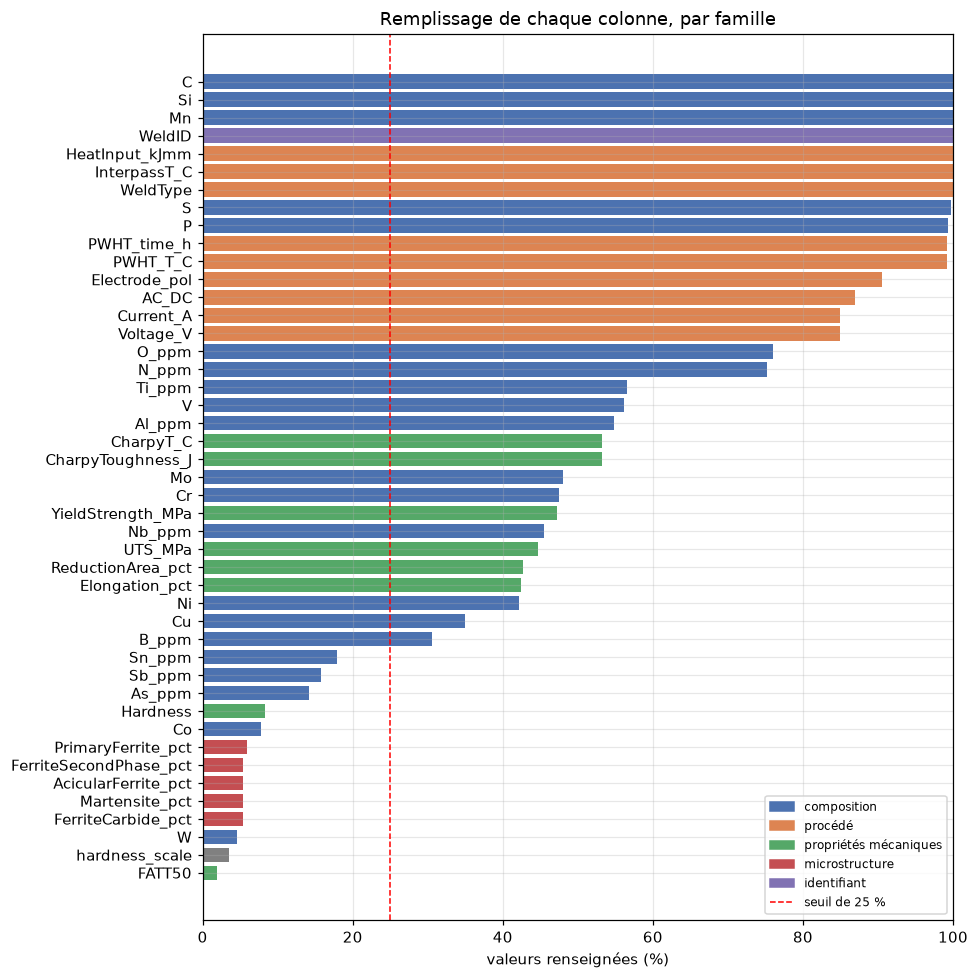

In [11]:
# Le taux de remplissage, famille par famille.
remplissage = propre.notna().mean().sort_values()
par_famille = []
for famille, colonnes in schema.items():
    presentes = [c for c in colonnes if c in propre.columns]
    par_famille.append({
        "famille": famille,
        "colonnes": len(presentes),
        "remplissage moyen": propre[presentes].notna().mean().mean(),
        "colonne la mieux remplie": propre[presentes].notna().mean().max(),
        "colonne la moins remplie": propre[presentes].notna().mean().min(),
    })
display(pd.DataFrame(par_famille).set_index("famille").round(3))

figure, axe = plt.subplots(figsize=(9, 9))
couleurs = {"composition": "#4C72B0", "procédé": "#DD8452",
            "propriétés mécaniques": "#55A868", "microstructure": "#C44E52",
            "identifiant": "#8172B3"}
appartenance = {c: f for f, cols in schema.items() for c in cols}
axe.barh(remplissage.index, 100 * remplissage.to_numpy(),
         color=[couleurs.get(appartenance.get(c, ""), "grey")
                for c in remplissage.index])
axe.axvline(25, color="red", linestyle="--", linewidth=1,
            label="seuil de 25 % retenu au notebook 3")
axe.set(xlabel="valeurs renseignées (%)", xlim=(0, 100),
        title="Remplissage de chaque colonne, par famille")
axe.legend(fontsize=9)
poignees = [plt.Rectangle((0, 0), 1, 1, color=c) for c in couleurs.values()]
axe.legend(poignees + axe.get_legend_handles_labels()[0],
           list(couleurs) + ["seuil de 25 %"], fontsize=8, loc="lower right")
figure.tight_layout()
figure.savefig(OUT / "remplissage_colonnes.png", dpi=150)
plt.show()

### 4.3 Conclusion : un mécanisme MAR structuré par le protocole

Le tableau croisé est sans équivoque. **Les lignes qui portent les deux familles
d'essais sont une petite minorité.** L'immense majorité porte une famille ou
l'autre, et presque jamais les deux.

Ce n'est évidemment pas du hasard. Un laboratoire qui étudie la résistance à la
traction réalise des essais de traction ; un laboratoire qui étudie la
résistance à la rupture fragile réalise des essais de résilience. **L'absence
est déterminée par le choix du protocole expérimental**, donc par une
caractéristique de l'étude et non par la valeur manquante elle-même. Nous sommes
en MAR structuré.

**Trois conséquences, qui portent tout le reste du projet.**

**On ne peut pas supprimer les lignes incomplètes.** Avec 45,6 % de valeurs
absentes et des absences organisées par bloc, cela ne laisserait presque rien, et
le peu qui resterait serait un sous-ensemble très particulier du corpus.

**On ne peut pas combiner traction et résilience dans une même cible.** Les deux
familles portent sur des soudures largement différentes. Construire une cible qui
exige les deux reviendrait à imputer massivement l'une à partir de l'autre, alors
qu'aucune relation fiable ne le permet. C'est pourquoi le notebook 2 traite les
deux familles séparément au lieu de les fusionner.

**L'absence est une information utilisable.** Puisqu'elle dépend du protocole,
elle renseigne indirectement sur le type d'étude, donc sur le type de soudure.
Pour les variables catégorielles nous créerons donc une catégorie `manquant`
plutôt que de remplacer par la valeur la plus fréquente. Le notebook 4 montrera
que les modèles pénalisés tirent effectivement parti de cette information.

## 5. Ce que coûte l'imputation, chiffré

Les modèles n'acceptent pas de valeurs absentes. Il faudra donc les remplacer,
et le notebook 3 détaille ce choix. Mais nous pouvons dès maintenant **chiffrer
le prix à payer**, et ce calcul explique un résultat du notebook 3 qui
paraîtrait sinon mystérieux.

### 5.1 Le raisonnement

Supposons une colonne dont une proportion `p` des valeurs est réellement
observée, le reste étant remplacé par une constante, par exemple la médiane.
Les valeurs imputées sont toutes identiques, donc elles ne contribuent pas à la
dispersion. La variance calculée sur la colonne complétée est ainsi réduite
d'un facteur `p` environ, et comme l'écart-type est la racine de la variance :

```
écart-type après imputation  =  écart-type réel  x  racine(p)
```

Le même raisonnement s'applique aux corrélations entre deux colonnes, qui sont
elles aussi contractées.

**L'imputation par une constante n'ajoute donc pas du bruit : elle écrase
systématiquement la variabilité**, et d'autant plus que la colonne est peu
renseignée. Une colonne remplie à 30 % voit son écart-type tomber à environ
55 % de sa valeur réelle.

### 5.2 La vérification sur nos données

Cette formule est une approximation. Nous la vérifions directement, en comparant
pour chaque colonne l'écart-type calculé sur les valeurs observées et celui
calculé après imputation par la médiane.

In [12]:
numeriques = [c for c in VARIABLES_ENTREE
              if pd.api.types.is_numeric_dtype(propre[c])]

lignes_effet = []
for colonne in numeriques:
    valeurs = propre[colonne]
    part_observee = valeurs.notna().mean()
    if part_observee < 0.05 or valeurs.std() == 0:
        continue
    complete = valeurs.fillna(valeurs.median())
    lignes_effet.append({
        "colonne": colonne,
        "part observée (p)": part_observee,
        "écart-type observé": valeurs.std(),
        "écart-type après imputation": complete.std(),
        "rapport mesuré": complete.std() / valeurs.std(),
        "racine de p (prédiction)": np.sqrt(part_observee),
    })

effet_imputation = pd.DataFrame(lignes_effet).set_index("colonne")
correlation = effet_imputation["rapport mesuré"].corr(
    effet_imputation["racine de p (prédiction)"])

print(f"{len(effet_imputation)} colonnes numériques examinées.")
print(f"Corrélation entre le rapport mesuré et la racine de p : "
      f"{correlation:.4f}")
display(effet_imputation.sort_values("part observée (p)")
        .head(8).round(4))

26 colonnes numériques examinées.
Corrélation entre le rapport mesuré et la racine de p : 0.9979


,part observée (p),écart-type observé,écart-type après imputation,rapport mesuré,racine de p (prédiction)
colonne,,,,,
Co,0.0781,0.3539,0.1001,0.2828,0.2794
As_ppm,0.1416,41.1753,16.8745,0.4098,0.3764
Sb_ppm,0.1574,35.5659,14.9175,0.4194,0.3967
Sn_ppm,0.1792,88.8990,37.5833,0.4228,0.4233
B_ppm,0.3051,10.1295,5.7800,0.5706,0.5523
Cu,0.3499,0.3230,0.2026,0.6273,0.5915
Ni,0.4219,0.7870,0.5391,0.6851,0.6495
Nb_ppm,0.4552,229.4217,167.2378,0.7290,0.6747


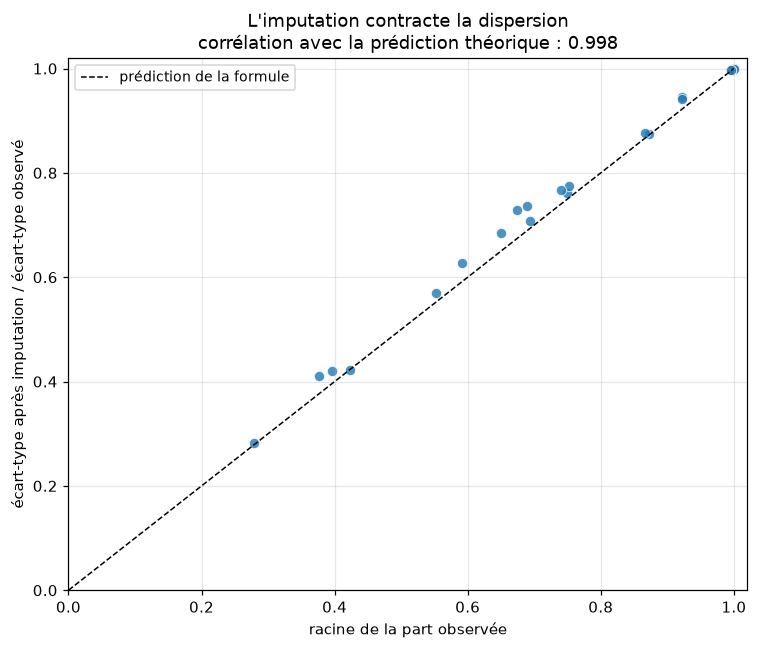

In [13]:
figure, axe = plt.subplots(figsize=(7, 6))
axe.scatter(effet_imputation["racine de p (prédiction)"],
            effet_imputation["rapport mesuré"], s=45, alpha=0.8,
            edgecolor="white", linewidth=0.6)
axe.plot([0, 1], [0, 1], "k--", linewidth=1,
         label="prédiction de la formule")
axe.set(xlabel="racine de la part observée", xlim=(0, 1.02), ylim=(0, 1.02),
        ylabel="écart-type après imputation / écart-type observé",
        title=f"L'imputation contracte la dispersion\n"
              f"corrélation avec la prédiction théorique : {correlation:.3f}")
axe.legend(fontsize=9)
figure.tight_layout()
figure.savefig(OUT / "cout_imputation.png", dpi=150)
plt.show()

### 5.3 Ce que cela annonce pour la suite

Les points s'alignent sur la diagonale avec une corrélation très élevée. **La
formule décrit donc correctement ce que l'imputation fait à nos données.**

Deux conséquences, et il faut les distinguer soigneusement car elles vont en
sens opposé.

**Pour l'exploration, le coût est réel.** Une analyse en composantes principales
repose entièrement sur les variances et les corrélations. Si celles-ci sont
contractées, les axes principaux expliquent mécaniquement moins de variance, et
la structure paraît plus plate qu'elle ne l'est. **Le notebook 3 montrera que
c'est exactement ce qui se produit**, et quantifiera l'écart en refaisant
l'analyse sur les colonnes bien renseignées.

**Pour la prédiction, le coût est nul.** Nous l'avons mesuré en comparant un
modèle entraîné sur des données imputées à un modèle capable de traiter
nativement les valeurs absentes, sans imputation. Sur les quatre propriétés
mécaniques, l'imputation par la médiane fait aussi bien, voire très légèrement
mieux. L'explication est qu'un arbre de décision place simplement une coupure à
côté de la constante d'imputation, ce qui revient à séparer les lignes
renseignées des autres : il récupère par un détour l'information d'absence.

Le détail de cette comparaison figure dans le notebook d'exploration
`notebooks/13_modeles_par_propriete.ipynb`, section 8.

**La formulation juste est donc : l'imputation par la médiane déforme la
structure des données et doit être critiquée pour ce qu'elle fait à l'analyse
exploratoire, et non pour un coût en performance prédictive, qui n'existe
pas.**

## 6. Un défaut résiduel que nous assumons

Le nettoyage traite les conventions d'écriture, pas les erreurs de contenu. Il
en reste, et nous en avons trouvé une d'une manière inattendue.

### 6.1 Comment nous l'avons trouvée

En examinant les deux soudures sur lesquelles notre meilleur modèle se trompait
le plus lourdement, nous avons constaté qu'elles partageaient une anomalie
physique : leur **limite d'élasticité est exactement égale à leur résistance à
la traction**.

C'est impossible dans un acier ductile. Le rapport entre ces deux grandeurs
s'appelle le taux d'écrouissage, et il mesure de combien le métal se renforce
entre le moment où il commence à se déformer durablement et celui où il rompt.
Sa valeur médiane dans notre corpus est d'environ 1,18. Un rapport exactement
égal à 1,000 décrirait un matériau qui rompt dès qu'il quitte son domaine
élastique.

**Nous signalons explicitement l'ordre dans lequel les choses se sont passées :
ce contrôle a été ajouté après coup, parce que les erreurs du modèle nous y ont
conduits.** C'est un usage légitime et reconnu d'un modèle prédictif : quand un
modèle bien construit se trompe lourdement sur un très petit nombre de points,
il faut examiner ces points avant de mettre en cause le modèle.

In [14]:
deux_resistances = propre[["UTS_MPa", "YieldStrength_MPa"]].dropna()
taux_ecrouissage = (deux_resistances["UTS_MPa"]
                    / deux_resistances["YieldStrength_MPa"])

SEUIL = 1.05
suspectes = taux_ecrouissage[taux_ecrouissage < SEUIL]
egalite_exacte = taux_ecrouissage[taux_ecrouissage == 1.0]

print(f"Lignes où les deux résistances sont connues : {len(deux_resistances)}")
print(f"Taux d'écrouissage : médiane {taux_ecrouissage.median():.3f}, "
      f"minimum {taux_ecrouissage.min():.3f}")
print(f"Lignes sous le seuil de {SEUIL} : {len(suspectes)}")
print(f"Lignes à exactement 1,000 : {len(egalite_exacte)}\n")

detail = propre.loc[suspectes.index,
                    ["WeldID", "YieldStrength_MPa", "UTS_MPa"]].copy()
detail["taux d'écrouissage"] = suspectes
detail["publication"] = detail["WeldID"].str.split("-").str[0]
display(detail.sort_values("taux d'écrouissage").round(3))

print("Publications d'origine des lignes à égalité exacte :")
print(detail.loc[egalite_exacte.index, "publication"].value_counts()
      .to_string())

Lignes où les deux résistances sont connues : 714
Taux d'écrouissage : médiane 1.179, minimum 1.000
Lignes sous le seuil de 1.05 : 5
Lignes à exactement 1,000 : 3

Publications d'origine des lignes à égalité exacte :
publication
Pat    3


,WeldID,YieldStrength_MPa,UTS_MPa,taux d'écrouissage,publication
row_id,,,,,
975,Pat-1981-S2Mo/BX200,554.0,554.0,1.000,Pat
980,Pat-1981-S4Mo/BX200,747.0,747.0,1.000,Pat
1020,Pat-1981-S4Mo/BX400,689.0,689.0,1.000,Pat
705,SurianEtAl-C-1991-0.05htCh,673.0,680.0,1.010,SurianEtAl
259,Evans-Cr/CMn-1989-1.0D-aw,692.0,723.0,1.045,Evans


### 6.2 Le diagnostic, et la décision

**Il faut distinguer deux cas parmi les lignes signalées.**

Les lignes à taux **exactement égal à 1,000** viennent toutes de la même
publication. Ce n'est donc pas une erreur dispersée au hasard, c'est un défaut
localisé. L'explication la plus économique est que cette publication ne
rapportait qu'une seule valeur de résistance, recopiée dans les deux colonnes
lors de la constitution du jeu de données. L'égalité exacte de deux mesures
physiques indépendantes est en elle-même improbable, même sans argument
métallurgique.

Les deux autres lignes, à 1,010 et 1,045, proviennent de publications
différentes. Ces valeurs sont basses mais pas impossibles : certains aciers
fortement alliés s'écrouissent très peu. Rien ne permet de les mettre en doute,
et notre seuil de 1,05 les attrape surtout parce qu'il est volontairement
prudent.

**Décision : nous signalons sans exclure.** Trois raisons.

Nous n'avons pas accès à la publication d'origine pour confirmer l'erreur.
Écarter des données sur une présomption, même forte, demande une vérification
dont nous ne disposons pas.

Deux des trois lignes suspectes appartiennent à notre ensemble de test. Les en
retirer après avoir constaté qu'elles dégradent nos résultats serait une faute
de méthode : **on ne nettoie pas un jeu de test au vu des erreurs qu'il
révèle**, sinon on mesure sa performance sur des données choisies pour être
favorables.

Enfin leur poids est négligeable : trois lignes sur plus de six cents, et la
pondération par soudure réduit encore leur influence.

**Ce qu'il faut en retenir** est que le corpus contient des défauts résiduels
malgré le nettoyage, ce qui est attendu pour une compilation de résultats publiés
par des laboratoires différents sur plusieurs décennies, et qu'un lecteur qui
verrait seulement le nuage de nos prédictions pourrait croire à une défaillance
du modèle sur les soudures à haute résistance. Il sait maintenant que ce n'en est
pas une.

## 7. Ce que ce notebook établit

### 7.1 Les données

Le jeu brut compte 1652 lignes et 44 colonnes, dont **30 variables d'entrée**,
composition chimique et paramètres de procédé. Les propriétés mécaniques sont
exclues des entrées puisqu'elles constituent ce que l'on cherche à prédire. La
microstructure est écartée, parce qu'elle n'est observable qu'après la soudure.

Le nettoyage traite quatre familles de valeurs non numériques, avec une décision
explicite et comptabilisée pour chacune. **Le symbole `N` signifie « non
renseigné » et non « zéro »**, et le confondre aurait introduit des milliers de
faux zéros.

### 7.2 Les trois contraintes pour la suite

**La validation doit être faite par groupes.** Les 1652 lignes décrivent 624
soudures, et un découpage ordinaire laisserait la très grande majorité des lignes
de validation appartenir à une soudure déjà vue en apprentissage. Tous nos
protocoles utilisent `GroupKFold` et le vérifient par assertion.

**Chaque soudure doit peser un.** Une soudure testée vingt fois ne vaut pas
vingt soudures. Une pondération par l'inverse de l'effectif du groupe est
appliquée partout.

**Les deux familles d'essais ne peuvent pas être fusionnées.** Les absences
suivent le protocole expérimental, donc traction et résilience portent sur des
soudures largement différentes. Le notebook 2 les traite séparément.

### 7.3 Ce qui est quantifié et sera réutilisé

L'imputation par une constante contracte l'écart-type d'un facteur égal à la
racine de la part observée, vérifié sur nos données avec une corrélation très
élevée. **Cela aura un effet mesurable sur l'analyse en composantes principales
du notebook 3, et aucun effet sur la performance prédictive du notebook 4.**

### 7.4 Ce que nous ne pouvons pas corriger

Le corpus est **observationnel** : il compile des essais publiés, et non une
expérience où l'on aurait fait varier un paramètre à la fois. Les compositions
et les procédés y sont corrélés par les pratiques industrielles. Toute relation
que nos modèles trouveront sera donc une **association et non un effet causal**,
et nos recommandations devront être formulées en conséquence.

Il contient des **défauts résiduels** de contenu, dont trois lignes à taux
d'écrouissage impossible, signalées et conservées.

Il ne décrit pas la **microstructure** de façon exploitable, alors que c'est
l'intermédiaire physique entre la composition et les propriétés. Une part de ce
que nos modèles ne parviendront pas à expliquer tient probablement là.

In [15]:
recapitulatif = pd.DataFrame([
    {"grandeur": "lignes du fichier", "valeur": len(propre)},
    {"grandeur": "soudures distinctes", "valeur": groupes.nunique()},
    {"grandeur": "colonnes décrites", "valeur": len(nettoyage.COLUMNS)},
    {"grandeur": "variables d'entrée retenues", "valeur": len(VARIABLES_ENTREE)},
    # Calculee depuis le masque de nettoyage, pour que ce chiffre coincide
    # exactement avec celui du tableau des decisions de la section 2.
    {"grandeur": "part de valeurs absentes (%)",
     "valeur": round(100 * decisions.loc["manquant", "part"], 1)},
    {"grandeur": "lignes avec traction mesurée", "valeur": int(a_traction.sum())},
    {"grandeur": "lignes avec résilience mesurée",
     "valeur": int(a_resilience.sum())},
    {"grandeur": "lignes avec les deux", "valeur": les_deux},
]).set_index("grandeur")
display(recapitulatif)

effet_imputation.to_csv(OUT / "cout_imputation.csv", index_label="colonne")
decisions.to_csv(OUT / "decisions_nettoyage.csv", index_label="motif")
recapitulatif.to_csv(OUT / "recapitulatif.csv", index_label="grandeur")
detail.to_csv(OUT / "lignes_suspectes.csv", index_label="row_id")

print(f"\nFichiers produits dans {OUT.relative_to(ROOT)} :")
for chemin in sorted(OUT.iterdir()):
    print(f"   {chemin.name}")
print("\nLe notebook 2 construit la variable de qualité à prédire.")


Fichiers produits dans outputs/rendu1 :
   cout_imputation.csv
   cout_imputation.png
   decisions_nettoyage.csv
   lignes_suspectes.csv
   recapitulatif.csv
   remplissage_colonnes.png

Le notebook 2 construit la variable de qualité à prédire.


,valeur
grandeur,
lignes du fichier,1652.0
soudures distinctes,624.0
colonnes décrites,44.0
variables d'entrée retenues,30.0
part de valeurs absentes (%),45.6
lignes avec traction mesurée,738.0
lignes avec résilience mesurée,879.0
lignes avec les deux,144.0
